In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import pandas as pd

df = pd.read_csv("eda_student_performance_500.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

Dataset loaded successfully!
Dataset Shape: (49, 1)

First 5 Rows:


,Area_sqft\tBedrooms\tBathrooms\tAge_years\tGarage_cars\tDistance_km\tFloor_no\tCrime_rate\tSchool_dist_km\tIncome_lakhs\tPrice_lakhs
0,1998.2\t4\t3\t40.0\t0\t8.36\t3\t3.561\t4.1\t13...
1,4302.9\t3\t2\t22.0\t0\t23.62\t11\t2.805\t3.56\...
2,3428.0\t5\t3\t24.0\t1\t3.86\t19\t4.417\t2.91\t...
3,2894.6\t1\t2\t19.0\t1\t3.19\t9\t0.822\t3.59\t1...
4,1124.1\t5\t1\t37.0\t0\t11.48\t10\t6.078\t2.24\...



Last 5 Rows:


,Area_sqft\tBedrooms\tBathrooms\tAge_years\tGarage_cars\tDistance_km\tFloor_no\tCrime_rate\tSchool_dist_km\tIncome_lakhs\tPrice_lakhs
44,1535.1\t5\t3\t23.0\t1\t27.47\t14\t6.822\t1.92\...
45,3150.1\t1\t1\t15.0\t2\t17.4\t14\t2.36\t4.1\t97...
46,1746.8\t5\t1\t27.0\t1\t6.3\t16\t5.16\t1.46\t13...
47,2580.3\t2\t2\t11.0\t1\t5.05\t7\t2.582\t0.6\t93...
48,2686.8\t1\t3\t17.0\t0\t17.72\t19\t7.668\t0.92\...


In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Area_sqft\tBedrooms\tBathrooms\tAge_years\tGarage_cars\tDistance_km\tFloor_no\tCrime_rate\tSchool_dist_km\tIncome_lakhs\tPrice_lakhs    0
dtype: int64

Missing Value Percentage:
Area_sqft\tBedrooms\tBathrooms\tAge_years\tGarage_cars\tDistance_km\tFloor_no\tCrime_rate\tSchool_dist_km\tIncome_lakhs\tPrice_lakhs    0.0
dtype: float64

Duplicate Records:
0


In [11]:
print("Descriptive Statistics:")
display(df.describe().round(2))

print("\nMean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nStandard Deviation:")
display(df.std(numeric_only=True))

print("\nSkewness:")
display(df.skew(numeric_only=True))

Descriptive Statistics:


,Area_sqft\tBedrooms\tBathrooms\tAge_years\tGarage_cars\tDistance_km\tFloor_no\tCrime_rate\tSchool_dist_km\tIncome_lakhs\tPrice_lakhs
count,49
unique,49
top,1998.2\t4\t3\t40.0\t0\t8.36\t3\t3.561\t4.1\t13...
freq,1



Mean:


Series([], dtype: float64)


Median:


Series([], dtype: float64)


Standard Deviation:


Series([], dtype: float64)


Skewness:


Series([], dtype: float64)

In [14]:
for col in numeric_cols:

    plt.figure(figsize=(9, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

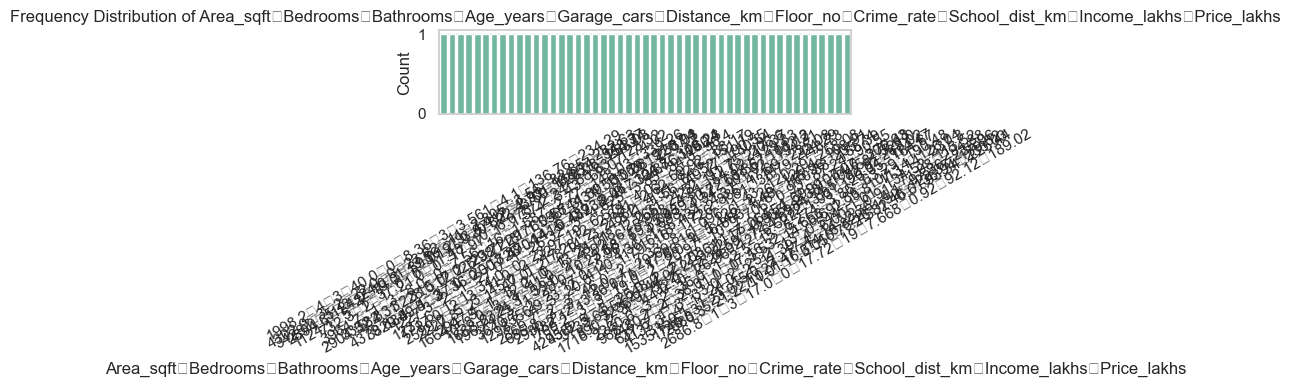

In [15]:
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=col
    )

    plt.title(f"Frequency Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=30)

    plt.tight_layout()

In [18]:
for col in categorical_cols:

    counts = df[col].value_counts()

    if len(counts) <= 5:

        plt.figure(figsize=(7, 6))

        plt.pie(
            counts,
            labels=counts.index,
            autopct='%1.1f%%',
            startangle=90
        )

        plt.title(f"Proportion of {col}")
        plt.axis('equal')

        plt.show()

In [20]:
study_trend = (
    df.groupby('Study_Hours')['Exam_Score']
    .mean()
    .reset_index()
    .sort_values('Study_Hours')
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=study_trend,
    x='Study_Hours',
    y='Exam_Score',
    marker='o'
)

plt.title("Study Hours vs Average Examination Score")
plt.xlabel("Study Hours")
plt.ylabel("Average Exam Score")

plt.tight_layout()
plt.show()

KeyError: 'Study_Hours'